In [1]:
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets,transforms
from torch.utils.data import Dataset,DataLoader

In [2]:
train_data=datasets.FashionMNIST(root="/content/sample_data",
                                 download=True
                                 ,train=True,
                                 transform=transforms.ToTensor())

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.70MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 51.2MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.5MB/s]


In [3]:
test_data=datasets.FashionMNIST(root="/content/sample_data",
                                 download=True
                                 ,train=False,
                                 transform=transforms.ToTensor())

In [4]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: /content/sample_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [5]:
test_data

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: /content/sample_data
    Split: Test
    StandardTransform
Transform: ToTensor()

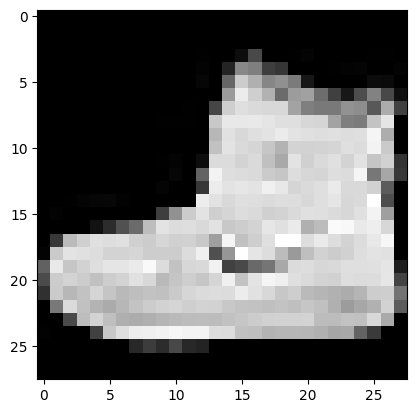

In [6]:
import matplotlib.pyplot as  plt
plt.imshow(train_data[0][0].squeeze(),cmap="grey")


In [7]:
classes=train_data.classes

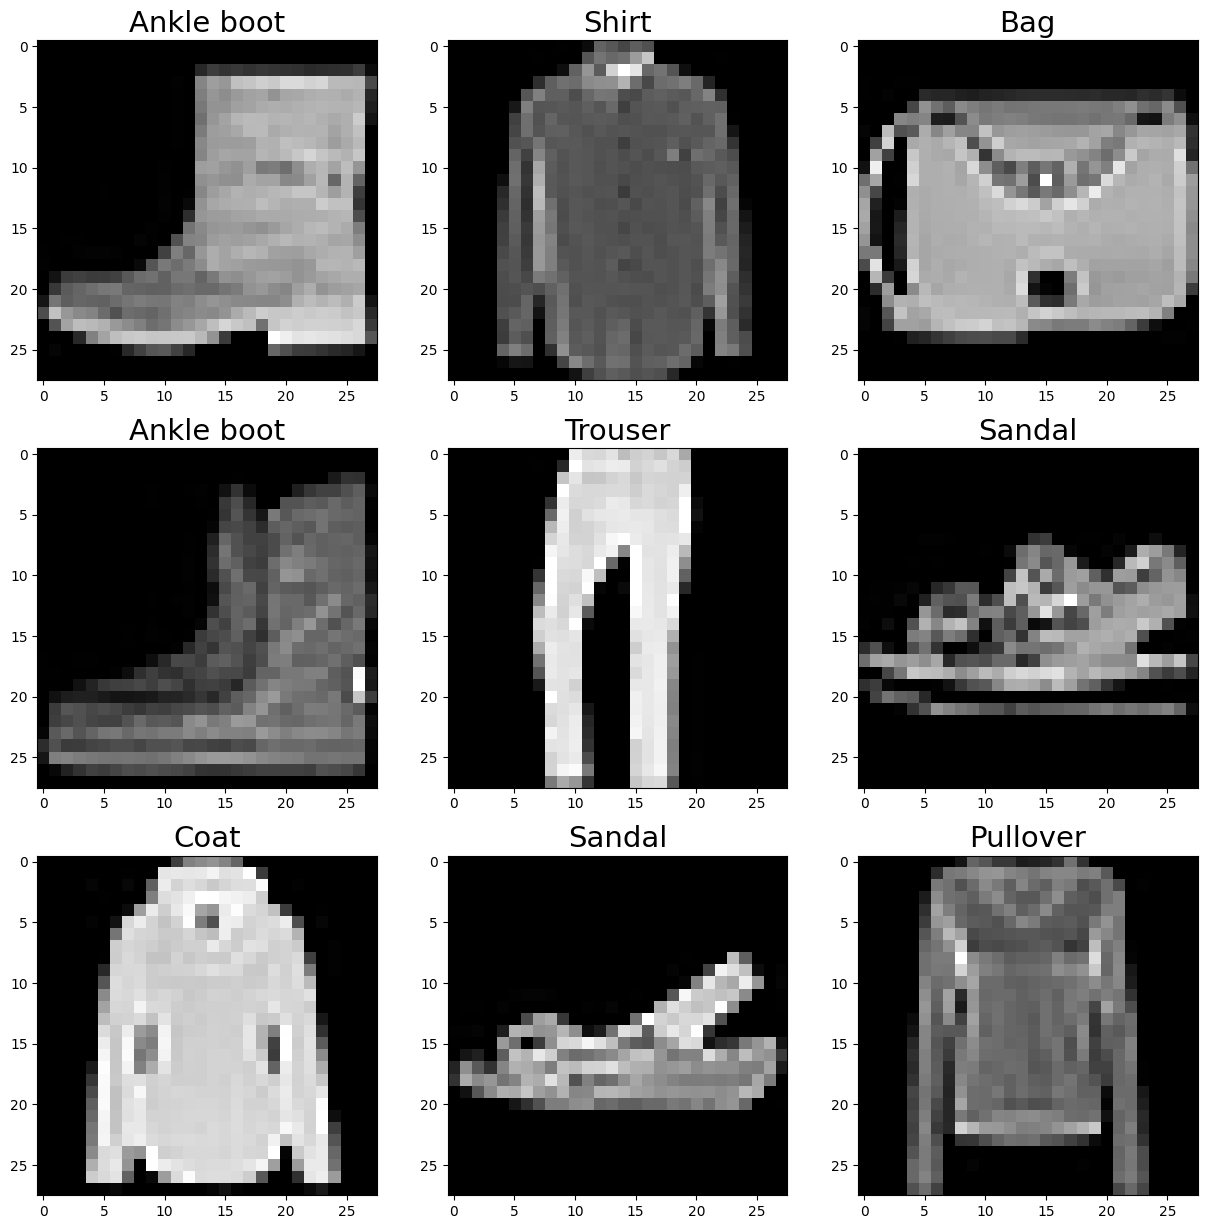

In [8]:
torch.manual_seed(42)
fig,axes=plt.subplots(nrows=3,ncols=3,figsize=(15,15))
axes=axes.flatten()
for i,ax in enumerate(axes):
  image_index=torch.randint(low=0,high=60000,size=()).item()
  img,label=train_data[image_index]
  ax.imshow(img.squeeze(),cmap="grey")
  ax.set_title(classes[label],fontsize=21)
plt.show()





In [9]:
train_dataloader=DataLoader(train_data,batch_size=128,shuffle=True)


In [10]:
test_dataloader=DataLoader(test_data,batch_size=128,shuffle=False)


In [11]:
print(f"Number of batches for train dataset :{len(train_dataloader)}")
print(f"Number of batches for test dataset :{len(test_dataloader)}")


Number of batches for train dataset :469
Number of batches for test dataset :79


In [12]:
train_Features_batches,train_labels_batches=next(iter(train_dataloader))
train_Features_batches.shape,train_labels_batches.shape

(torch.Size([128, 1, 28, 28]), torch.Size([128]))

In [13]:
28*28

784

In [32]:
class Base_Model(nn.Module):
  def __init__(self):
    super().__init__()
    self.Layer1=nn.Linear(in_features=784,out_features=500)
    self.Layer2=nn.Linear(in_features=500,out_features=250)
    self.layer3=nn.Linear(in_features=250,out_features=100)
    self.Layer4=nn.Linear(in_features=100,out_features=10)
    self._init_weights()


  def _init_weights(self):
      for m in self.modules():
        if isinstance(m, nn.Linear):
          nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
          if m.bias is not None:
            nn.init.constant_(m.bias, 0.0)


  def forward(self,x):
   x=torch.flatten(x,start_dim=1)
   return self.Layer4(
        torch.relu(
            self.layer3(
                torch.relu(
                    self.Layer2(
                        torch.relu(
                            self.Layer1(
                                x
                            )
                        )
                    )
                )
            )
        )
    )

In [33]:
model_0=Base_Model()
criterion=nn.CrossEntropyLoss()


In [38]:
optim=torch.optim.Adam(model_0.parameters(),lr=0.001)

In [34]:
torch.manual_seed(42)
def Train_Model(model,criterion,optim,train_loader,test_loader,n_epochs,device):
  model.to(device)
  for epoch in range(n_epochs):
    # train Model
    model.train()
    print(f"Epoch {epoch+1}:")
    loss=0
    correct_predictions=0
    total_samples=0
    for batch,(X,Y)in enumerate(train_loader):
      X=X.to(device)
      Y=Y.to(device)
      images=X.squeeze()
      train_preds=model(X)
      Loss=criterion(train_preds,Y)
      loss+=Loss.item()
      optim.zero_grad()
      Loss.backward()
      optim.step()
      _,predictions=torch.max(train_preds,dim=1)
      correct_predictions+=(predictions==Y).sum().item()
      total_samples+=Y.size(0)
    average_train_Loss=loss/len(train_loader)
    train_accuracy=(correct_predictions/total_samples)*100
    correct_predictions=0
    total_samples=0
    loss=0
    # Test Model
    model.eval()
    with torch.inference_mode():
      for batch,(X,Y)in enumerate(test_loader):
        X=X.to(device)
        Y=Y.to(device)
        images=X.squeeze()
        test_preds=model(X)
        Loss=criterion(test_preds,Y)
        loss+=Loss.item()
        _,predictions=torch.max(test_preds,dim=1)
        correct_predictions+=(predictions==Y).sum().item()
        total_samples+=Y.size(0)
      average_test_loss=loss/len(test_loader)
      test_accuracy=(correct_predictions/total_samples)*100
    print(f"\nTrain loss: {average_train_Loss:.5f} | Test loss: { average_test_loss:.5f}, Train acc={train_accuracy:.2f}%, Test acc: {test_accuracy:.2f}%\n")
  return model



















In [39]:
model_0=Train_Model(model_0
                    ,criterion
                    ,optim
                    ,train_dataloader
                    ,test_dataloader
                    ,20
                    ,"cuda")

Epoch 1:

Train loss: 0.16556 | Test loss: 0.55394, Train acc=93.54, Test acc: 88.45%

Epoch 2:

Train loss: 0.16413 | Test loss: 0.55604, Train acc=93.51, Test acc: 88.40%

Epoch 3:

Train loss: 0.16335 | Test loss: 0.55898, Train acc=93.58, Test acc: 88.46%

Epoch 4:

Train loss: 0.16289 | Test loss: 0.56319, Train acc=93.62, Test acc: 88.48%

Epoch 5:

Train loss: 0.16247 | Test loss: 0.57347, Train acc=93.64, Test acc: 88.52%

Epoch 6:

Train loss: 0.16201 | Test loss: 0.57279, Train acc=93.60, Test acc: 88.53%

Epoch 7:

Train loss: 0.16167 | Test loss: 0.58418, Train acc=93.63, Test acc: 88.46%

Epoch 8:

Train loss: 0.16131 | Test loss: 0.58698, Train acc=93.67, Test acc: 88.42%

Epoch 9:

Train loss: 0.16101 | Test loss: 0.58756, Train acc=93.73, Test acc: 88.44%

Epoch 10:

Train loss: 0.16064 | Test loss: 0.59151, Train acc=93.70, Test acc: 88.47%

Epoch 11:

Train loss: 0.16025 | Test loss: 0.59814, Train acc=93.74, Test acc: 88.35%

Epoch 12:

Train loss: 0.15988 | Test los

In [40]:
class Le_Net5(nn.Module):
  def __init__(self):
    super().__init__()
    self.block1=nn.Sequential(
        nn.Conv2d(in_channels=1,out_channels=6,kernel_size=(5,5),stride=1,padding=2),
        nn.Tanh(),
        nn.AvgPool2d(stride=2,padding=0,kernel_size=(2,2))
    )
    self.block2=nn.Sequential(
        nn.Conv2d(in_channels=6,out_channels=16,kernel_size=(5,5),stride=1),
        nn.Tanh(),
        nn.AvgPool2d(stride=2,padding=0,kernel_size=(2,2))
    )
    self.FC1=nn.Linear(in_features=400,out_features=120)
    self.FC2=nn.Linear(in_features=120,out_features=84)
    self.FC3=nn.Linear(in_features=84,out_features=10)
    self._init_weights()


  def _init_weights(self):
      for m in self.modules():
        if isinstance(m, nn.Linear):
          nn.init.xavier_uniform_(m.weight)
          if m.bias is not None:
            nn.init.constant_(m.bias, 0.0)


  def forward(self,x):
    x=self.block1(x)
    x=self.block2(x)
    x=x.flatten(start_dim=1)
    x=self.FC1(x)
    x=torch.tanh(x)
    x=self.FC2(x)
    x=torch.tanh(x)
    x=self.FC3(x)

    return x


In [41]:
le_Net5=Le_Net5()


In [46]:
optim=torch.optim.Adam(le_Net5.parameters(),lr=0.0001)

In [47]:
le_Net5=Train_Model(le_Net5
                    ,criterion
                    ,optim
                    ,train_dataloader
                    ,test_dataloader
                    ,20
                    ,"cuda")

Epoch 1:

Train loss: 0.14688 | Test loss: 0.29192, Train acc=94.77, Test acc: 89.97%

Epoch 2:

Train loss: 0.14133 | Test loss: 0.29121, Train acc=95.02, Test acc: 89.82%

Epoch 3:

Train loss: 0.13904 | Test loss: 0.29071, Train acc=95.16, Test acc: 90.09%

Epoch 4:

Train loss: 0.13758 | Test loss: 0.29151, Train acc=95.19, Test acc: 89.96%

Epoch 5:

Train loss: 0.13618 | Test loss: 0.29190, Train acc=95.20, Test acc: 89.95%

Epoch 6:

Train loss: 0.13505 | Test loss: 0.29201, Train acc=95.29, Test acc: 89.99%

Epoch 7:

Train loss: 0.13348 | Test loss: 0.29244, Train acc=95.30, Test acc: 90.05%

Epoch 8:

Train loss: 0.13224 | Test loss: 0.29288, Train acc=95.38, Test acc: 90.02%

Epoch 9:

Train loss: 0.13121 | Test loss: 0.29463, Train acc=95.44, Test acc: 90.11%

Epoch 10:

Train loss: 0.13003 | Test loss: 0.29546, Train acc=95.52, Test acc: 89.99%

Epoch 11:

Train loss: 0.12897 | Test loss: 0.29558, Train acc=95.52, Test acc: 90.08%

Epoch 12:

Train loss: 0.12778 | Test los

In [88]:
class Modified_Le_Net5(nn.Module):
  def __init__(self,p=0.5):
    super().__init__()
    self.block1=nn.Sequential(
        nn.Conv2d(in_channels=1,out_channels=6,kernel_size=(5,5),stride=1,padding=2),
        nn.ReLU(),
    )
    self.block2=nn.Sequential(
        nn.Conv2d(in_channels=6,out_channels=16,kernel_size=(5,5),stride=1),
         nn.ReLU(),
        nn.MaxPool2d(stride=2,padding=0,kernel_size=(2,2))
    )
    self.block3=nn.Sequential(
        nn.Conv2d(in_channels=16,out_channels=32,kernel_size=(5,5),stride=1,padding=1),
         nn.ReLU(),
        nn.MaxPool2d(stride=2,padding=0,kernel_size=(2,2))
    )
    self.dropout=nn.Dropout(p=p)
    self.FC1=nn.Linear(in_features=800,out_features=400)
    self.FC2=nn.Linear(in_features=400,out_features=200)
    self.FC3=nn.Linear(in_features=200,out_features=100)
    self.FC4=nn.Linear(in_features=100,out_features=50)
    self.FC5=nn.Linear(in_features=50,out_features=10)
    self._init_weights()


  def _init_weights(self):
      for m in self.modules():
        if isinstance(m, nn.Linear):
          nn.init.xavier_uniform_(m.weight)
          if m.bias is not None:
            nn.init.constant_(m.bias, 0.0)


  def forward(self,x):
    x=self.block1(x)
    x=self.block2(x)
    x=self.block3(x)
    x=x.flatten(start_dim=1)
    x=self.FC1(x)
    x=self.dropout(torch.relu(x))
    x=self.FC2(x)
    x=self.dropout(torch.relu(x))
    x=self.FC3(x)
    x=self.dropout(torch.relu(x))
    x=self.FC4(x)
    x=self.dropout(torch.relu(x))
    x=self.FC5(x)
    return x


In [89]:
Mle_Net5=Modified_Le_Net5()


In [93]:
optim=torch.optim.Adam(Mle_Net5.parameters(),lr=0.0001)

In [94]:
modified_Model=Train_Model(Mle_Net5
                    ,criterion
                    ,optim
                    ,train_dataloader
                    ,test_dataloader
                    ,20
                    ,"cuda")

Epoch 1:

Train loss: 0.19118 | Test loss: 0.28454, Train acc=93.76, Test acc: 91.93%

Epoch 2:

Train loss: 0.17819 | Test loss: 0.29701, Train acc=94.17, Test acc: 91.95%

Epoch 3:

Train loss: 0.17333 | Test loss: 0.29092, Train acc=94.26, Test acc: 91.96%

Epoch 4:

Train loss: 0.17130 | Test loss: 0.29228, Train acc=94.34, Test acc: 92.06%

Epoch 5:

Train loss: 0.16783 | Test loss: 0.29383, Train acc=94.51, Test acc: 91.99%

Epoch 6:

Train loss: 0.16367 | Test loss: 0.29616, Train acc=94.62, Test acc: 92.01%

Epoch 7:

Train loss: 0.16008 | Test loss: 0.30875, Train acc=94.72, Test acc: 92.05%

Epoch 8:

Train loss: 0.15940 | Test loss: 0.30290, Train acc=94.86, Test acc: 92.17%

Epoch 9:

Train loss: 0.15754 | Test loss: 0.31014, Train acc=94.93, Test acc: 92.06%

Epoch 10:

Train loss: 0.15307 | Test loss: 0.30943, Train acc=94.97, Test acc: 92.17%

Epoch 11:

Train loss: 0.14654 | Test loss: 0.31600, Train acc=95.12, Test acc: 92.14%

Epoch 12:

Train loss: 0.14891 | Test los

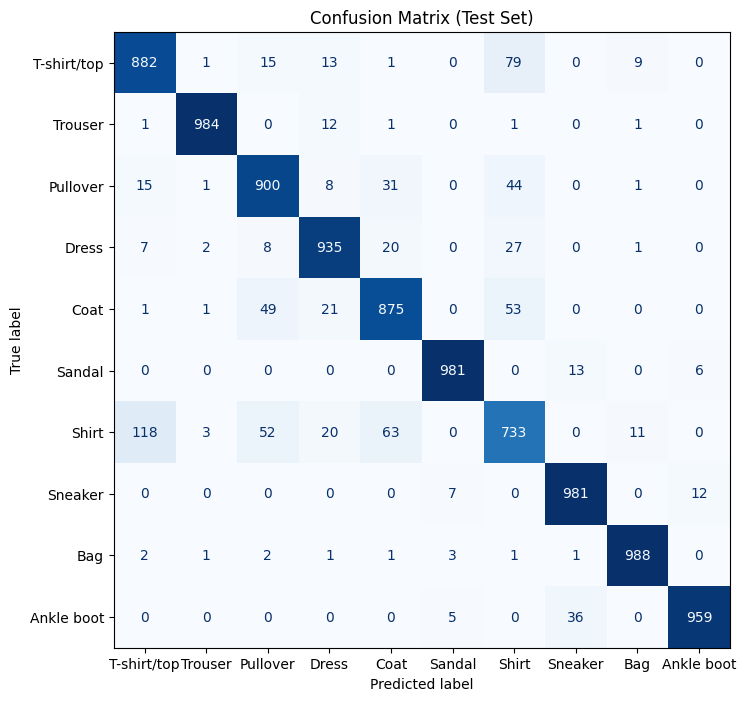

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      1000
           1       0.99      0.98      0.99      1000
           2       0.88      0.90      0.89      1000
           3       0.93      0.94      0.93      1000
           4       0.88      0.88      0.88      1000
           5       0.98      0.98      0.98      1000
           6       0.78      0.73      0.76      1000
           7       0.95      0.98      0.97      1000
           8       0.98      0.99      0.98      1000
           9       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



In [95]:
all_preds = []
all_labels = []
modified_Model.eval()
with torch.inference_mode():
    for X, Y in test_dataloader:
        X = X.to("cuda")
        Y = Y.to("cuda")
        test_preds = modified_Model(X)
        _, predictions = torch.max(test_preds, dim=1)

        all_preds.append(predictions.cpu())   # move back to CPU
        all_labels.append(Y.cpu())

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()


import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (Test Set)")
plt.show()

print(classification_report(y_true, y_pred))